In [1]:
!pip install -q pynvml

In [3]:
import gc
import time

import numpy as np
import pandas as pd
import torch
from torch.profiler import profile, ProfilerActivity
from tqdm.auto import tqdm

from models import get_model
from equations import flops, memory, bytes_moved, latency, energy
from calibrate import fit_latency, fit_energy

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

torch.manual_seed(42)
rng = np.random.default_rng(42)

import pynvml

pynvml.nvmlInit()
handle = pynvml.nvmlDeviceGetHandleByIndex(0)

device = torch.device("cuda:0")
model = get_model().to(device=device, dtype=torch.float32).eval()

## Measurement grid

In [4]:
S = [32, 64, 128, 224, 256, 384, 512]
B = [1, 2, 4, 8, 16, 32, 64, 128, 256]

S_rand = rng.choice(
    sorted(set(range(32, 513, 16)) - set(S)),
    size=4, replace=False,
).tolist()

B_rand = rng.choice(
    sorted(set(range(1, 257)) - set(B)),
    size=3, replace=False,
).tolist()

grid = [
    (s, b)
    for s in sorted(S + S_rand)
    for b in sorted(B + B_rand)
]

## Benchmark

In [7]:
import time

@torch.inference_mode()
def benchmark(s, b):
    row = {
        "S": s,
        "B": b,
        "flops": flops(s, b),
        "flops_profiler": np.nan,
        "memory_pred": memory(s, b),
        "memory": np.nan,
        "memory_baseline": np.nan,
        "latency": np.nan,
        "energy": np.nan,
        "latency_energy": np.nan,
    }

    try:
        x = torch.randn(b, 3, s, s, device=device)

        for _ in range(3):
            y = model(x)
            del y

        torch.cuda.synchronize(device)

        row["memory_baseline"] = torch.cuda.memory_allocated(device)
        torch.cuda.reset_peak_memory_stats(device)

        y = model(x)
        torch.cuda.synchronize(device)

        row["memory"] = torch.cuda.max_memory_allocated(device)
        del y

    except torch.cuda.OutOfMemoryError:
        row["memory"] = np.nan
        return row

    times = []
    for _ in range(10):
        torch.cuda.synchronize(device)
        start = time.perf_counter()

        y = model(x)
        torch.cuda.synchronize(device)

        times.append(time.perf_counter() - start)
        del y

    row["latency"] = float(np.median(times))

    torch.cuda.synchronize(device)

    energy_start = pynvml.nvmlDeviceGetTotalEnergyConsumption(handle)
    start = time.perf_counter()
    count = 0

    while True:
        y = model(x)
        torch.cuda.synchronize(device)
        del y
        count += 1

        if time.perf_counter() - start >= 1.0:
            break

    elapsed = time.perf_counter() - start
    energy_end = pynvml.nvmlDeviceGetTotalEnergyConsumption(handle)

    if energy_end > energy_start:
        row["energy"] = (energy_end - energy_start) / 1000 / count
        row["latency_energy"] = elapsed / count

    try:
        with profile(
            activities=[ProfilerActivity.CPU],
            record_shapes=True,
            with_flops=True,
        ) as prof:
            y = model(x)
            torch.cuda.synchronize(device)
            del y

        row["flops_profiler"] = sum(
            event.flops or 0 for event in prof.key_averages()
        )

    except torch.cuda.OutOfMemoryError:
        row["flops_profiler"] = np.nan

    return row

## Evaluation

In [8]:
rows = []

for s, b in tqdm(grid):
    gc.collect()
    torch.cuda.empty_cache()

    rows.append(benchmark(s, b))

    gc.collect()
    torch.cuda.empty_cache()


  0%|          | 0/132 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


## Fit latency and energy

In [9]:
import json
from pathlib import Path

results = pd.DataFrame(rows)

results["is_validation"] = ~(
    results["S"].isin(S) & results["B"].isin(B)
)

data = results.copy()
data["flops"] = data["B"] * (17798 * data["S"]**2 + 313700)
data["bytes_moved"] = bytes_moved(data["S"], data["B"])
data = data.replace([np.inf, -np.inf], np.nan)

train = data[~data["is_validation"]]

latency_train = train.dropna(subset=["latency"])
latency_train = latency_train[latency_train["latency"] > 0]

energy_train = train.dropna(subset=["energy", "latency_energy"])
energy_train = energy_train[
    (energy_train["energy"] > 0)
    & (energy_train["latency_energy"] > 0)
]

theta_latency = fit_latency(latency_train)
energy_coefficients = fit_energy(energy_train)
theta_energy = (*energy_coefficients, theta_latency)

s = results["S"].to_numpy()
b = results["B"].to_numpy()

results["latency_pred"] = latency(s, b, theta_latency)
results["energy_pred"] = energy(s, b, theta_energy)

## Plots

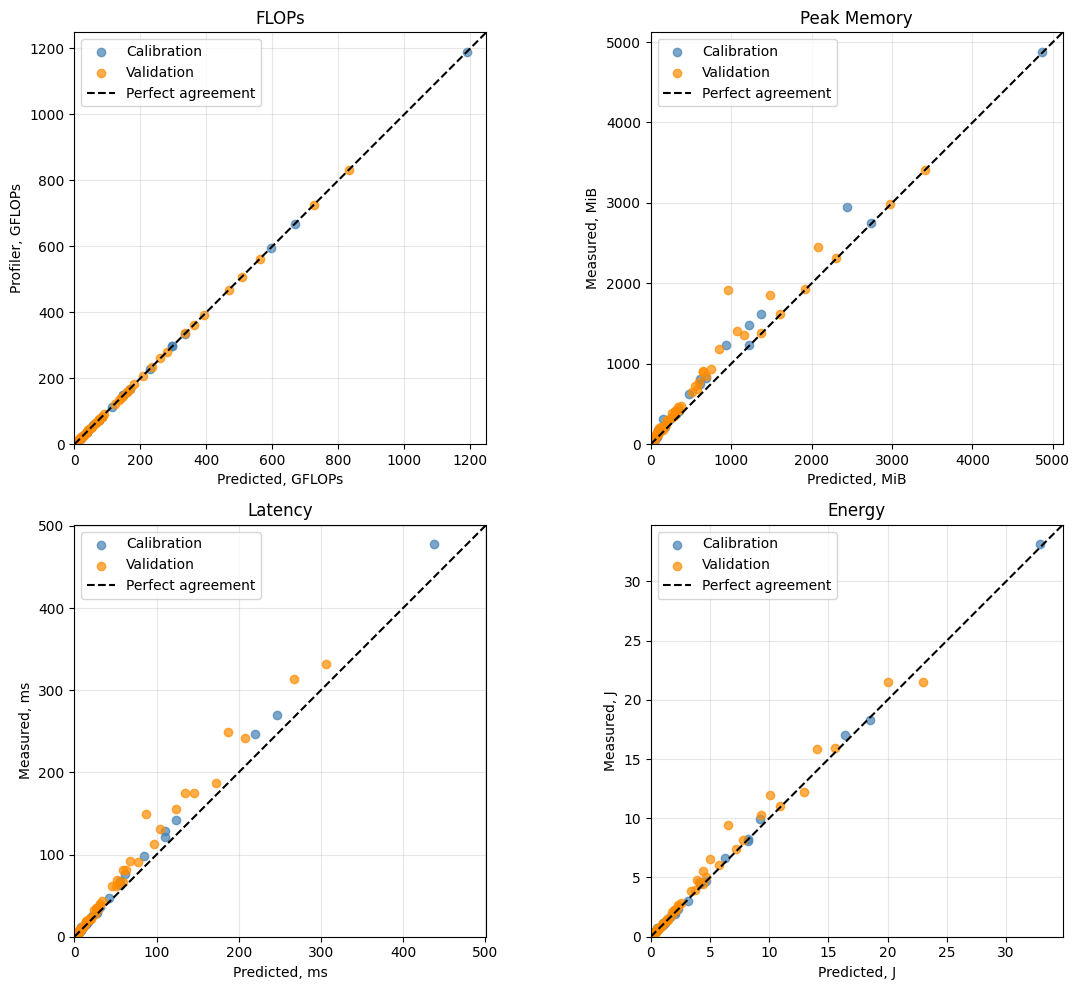

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

plots = [
    ("flops", "flops_profiler", 1e9, "FLOPs", "GFLOPs"),
    ("memory_pred", "memory", 2**20, "Peak Memory", "MiB"),
    ("latency_pred", "latency", 1e-3, "Latency", "ms"),
    ("energy_pred", "energy", 1, "Energy", "J"),
]

for ax, (pred, measured, scale, title, unit) in zip(axes.flat, plots):
    points = (
        results[[pred, measured, "is_validation"]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    for validation, label, color in [
        (False, "Calibration", "steelblue"),
        (True, "Validation", "darkorange"),
    ]:
        subset = points[points["is_validation"] == validation]

        ax.scatter(
            subset[pred] / scale,
            subset[measured] / scale,
            color=color,
            label=label,
            alpha=0.7,
        )

    if not points.empty:
        limit = max(points[pred].max(), points[measured].max()) / scale * 1.05
        ax.plot([0, limit], [0, limit], "k--", label="Perfect agreement")
        ax.set_xlim(0, limit)
        ax.set_ylim(0, limit)

    ax.set_title(title)
    ax.set_xlabel(f"Predicted, {unit}")
    ax.set_ylabel(
        f"Profiler, {unit}" if pred == "flops" else f"Measured, {unit}"
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

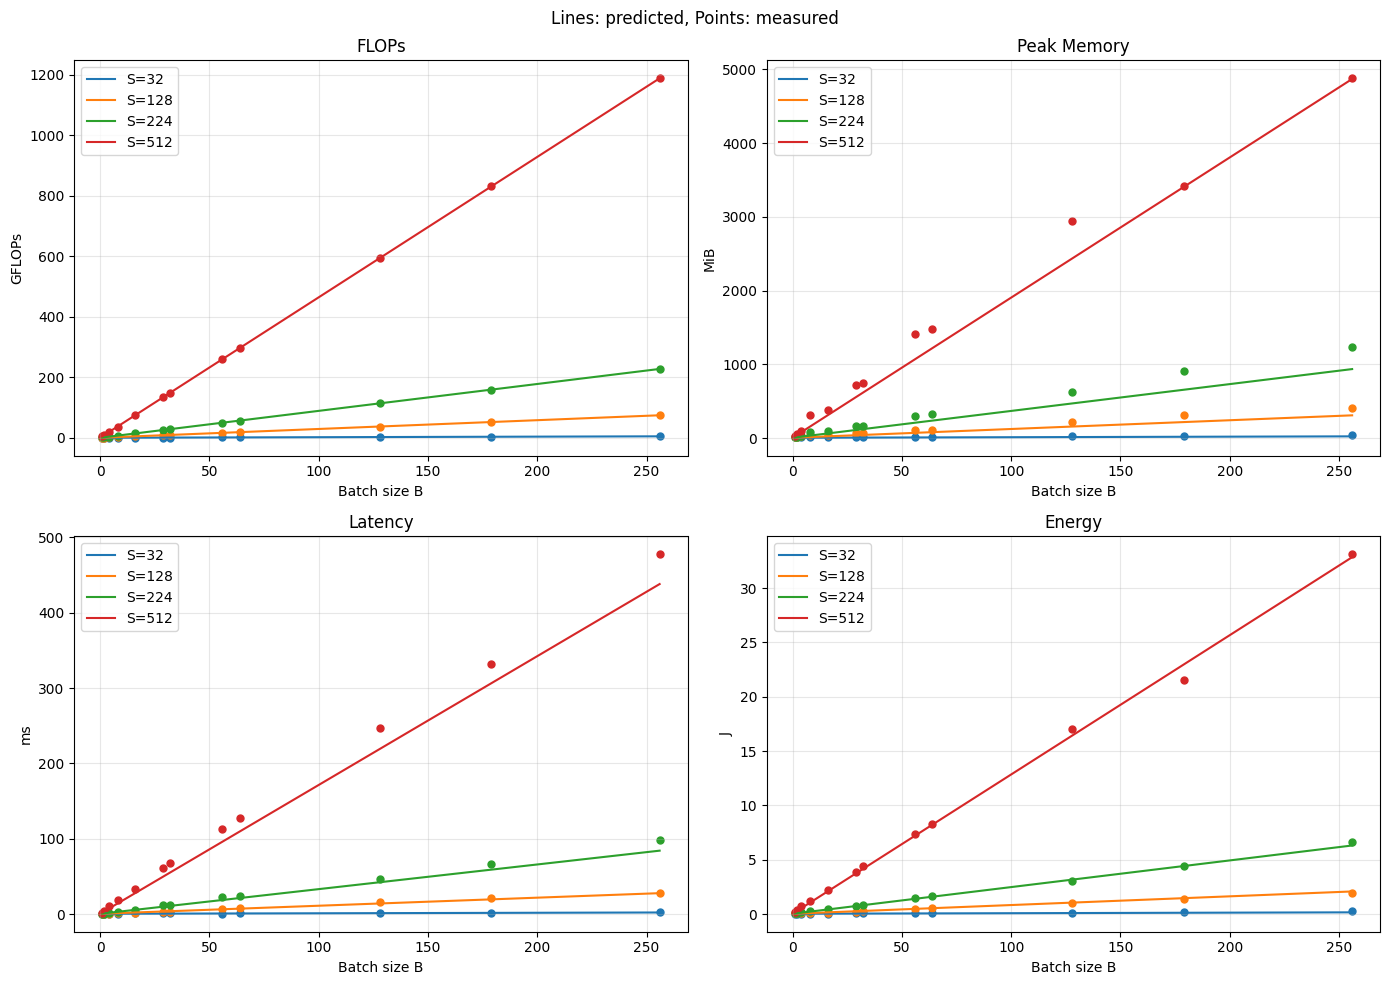

In [12]:
plots = [
    ("flops", "flops_profiler", 1e9, "FLOPs", "GFLOPs"),
    ("memory_pred", "memory", 2**20, "Peak Memory", "MiB"),
    ("latency_pred", "latency", 1e-3, "Latency", "ms"),
    ("energy_pred", "energy", 1, "Energy", "J"),
]

selected_sizes = [32, 128, 224, 512]
colors = plt.cm.tab10(np.arange(len(selected_sizes)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (pred, measured, scale, title, unit) in zip(axes.flat, plots):
    for size, color in zip(selected_sizes, colors):
        subset = (
            results[results["S"] == size]
            .sort_values("B")
            .replace([np.inf, -np.inf], np.nan)
        )

        ax.plot(
            subset["B"],
            subset[pred] / scale,
            color=color,
            label=f"S={size}",
        )
        ax.scatter(
            subset["B"],
            subset[measured] / scale,
            color=color,
            s=25,
        )

    ax.set_title(title)
    ax.set_xlabel("Batch size B")
    ax.set_ylabel(unit)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Lines: predicted, Points: measured")
plt.tight_layout()
plt.show()

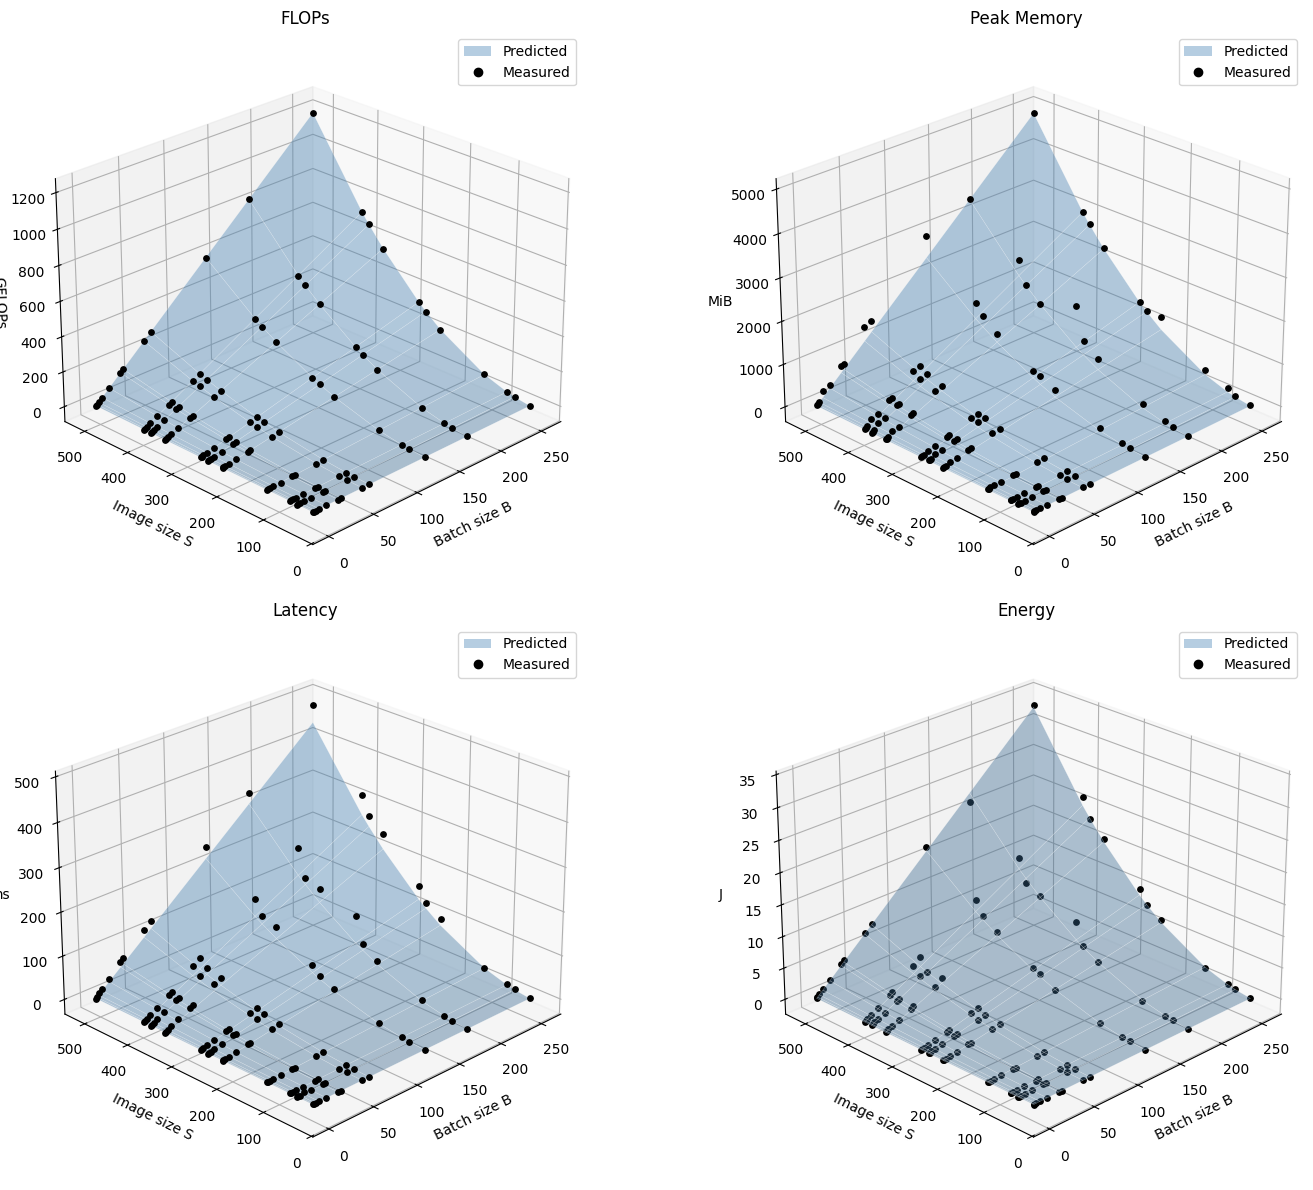

In [14]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

batch_grid, size_grid = np.meshgrid(
    np.sort(results["B"].unique()),
    np.sort(results["S"].unique()),
)

surfaces = [
    flops(size_grid, batch_grid),
    memory(size_grid, batch_grid),
    latency(size_grid, batch_grid, theta_latency),
    energy(size_grid, batch_grid, theta_energy),
]

fig = plt.figure(figsize=(16, 12))

legend = [
    Patch(facecolor="steelblue", alpha=0.4, label="Predicted"),
    Line2D(
        [0], [0], marker="o", linestyle="none",
        color="black", label="Measured",
    ),
]

for i, ((_, measured, scale, title, unit), surface) in enumerate(
    zip(plots, surfaces), 1
):
    ax = fig.add_subplot(2, 2, i, projection="3d")

    ax.plot_surface(
        batch_grid,
        size_grid,
        surface / scale,
        color="steelblue",
        alpha=0.4,
        edgecolor="white",
        linewidth=0.3,
    )

    points = (
        results[["B", "S", measured]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    ax.scatter(
        points["B"],
        points["S"],
        points[measured] / scale,
        color="black",
        s=15,
        depthshade=False,
    )

    ax.set_title(title)
    ax.set_xlabel("Batch size B")
    ax.set_ylabel("Image size S")
    ax.set_zlabel(unit)
    ax.view_init(elev=25, azim=-135)
    ax.legend(handles=legend)

plt.tight_layout()
plt.show()